# Data Understanding – AI4I 2020 Predictive Maintenance Dataset

## Objective
This notebook performs initial inspection of the AI4I 2020 dataset to understand structure, variable types, data quality, and the distribution of the target variable (machine failure) prior to EDA and modeling.


## Notebook Metadata
- **Notebook:** 01_data_understanding.ipynb
- **Project:** Predictive Maintenance Analytics for Industrial Equipment
- **Dataset:** AI4I 2020 Predictive Maintenance Dataset
- **Purpose:** Initial data inspection before EDA, feature engineering, and modeling
- **Author(s):** Group 5

In [1]:
# Core libraries for data handling and numerical operations
import pandas as pd
import numpy as np

# Visualization libraries for quick exploratory plots
import matplotlib.pyplot as plt
import seaborn as sns

# Standard library modules for project path handling
import sys
from pathlib import Path

# Set default figure size for consistent notebook visuals
plt.rcParams["figure.figsize"] = (8, 5)

# Resolve project root so local modules from /src can be imported
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src" / "data_loader.py").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this project's folder in VS Code before running the notebook.")
for _path in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
sys.path.append(str(PROJECT_ROOT / "src"))

# Import reusable project functions for loading and inspecting cleaned data
from data_loader import load_cleaned_data, get_basic_info

# Load the cleaned dataset
df = load_cleaned_data()

# Preview the first few rows
df.head()

Out[1]: 
   UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
0    1     M14860    M                298.1  ...    0    0    0    0
1    2     L47181    L                298.2  ...    0    0    0    0
2    3     L47182    L                298.1  ...    0    0    0    0
3    4     L47183    L                298.2  ...    0    0    0    0
4    5     L47184    L                298.2  ...    0    0    0    0

[5 rows x 14 columns]


### Interpretation
The dataset contains both numerical and categorical variables. At this stage, special attention should be given to confirming whether each variable has the correct data type for later modeling and whether any columns require encoding.

## Dataset Overview
This section checks the dataset size, column types, and memory structure to confirm that the data loaded correctly and to identify any immediate type-related issues.

In [2]:
# Display the number of rows and columns in the dataset
print(f"Shape: {df.shape}")

# Print a blank line for better readability in the output
print()

# Show column names, non-null counts, and data types
# This helps confirm the dataset structure and identify any type issues
df.info()

Shape: (10000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: 

### Interpretation
The descriptive statistics provide an initial view of variable ranges and spread. These values help identify whether certain variables, such as rotational speed or tool wear, may contain unusually high or low observations that should be examined further during EDA.

## Descriptive Statistics
This section summarizes the central tendency and spread of the variables to identify unusual values and understand the overall data profile.

In [3]:
# Generate descriptive statistics for all columns
# include="all" ensures both numerical and categorical variables are summarized
# .T transposes the output to make it easier to read by variable
df.describe(include="all").T

Out[3]: 
                           count unique     top  ...     50%      75%      max
UDI                      10000.0    NaN     NaN  ...  5000.5  7500.25  10000.0
Product ID                 10000  10000  L57163  ...     NaN      NaN      NaN
Type                       10000      3       L  ...     NaN      NaN      NaN
Air temperature [K]      10000.0    NaN     NaN  ...   300.1    301.5    304.5
Process temperature [K]  10000.0    NaN     NaN  ...   310.1    311.1    313.8
Rotational speed [rpm]   10000.0    NaN     NaN  ...  1503.0   1612.0   2886.0
Torque [Nm]              10000.0    NaN     NaN  ...    40.1     46.8     76.6
Tool wear [min]          10000.0    NaN     NaN  ...   108.0    162.0    253.0
Machine failure          10000.0    NaN     NaN  ...     0.0      0.0      1.0
TWF                      10000.0    NaN     NaN  ...     0.0      0.0      1.0
HDF                      10000.0    NaN     NaN  ...     0.0      0.0      1.0
PWF                      10000.0    NaN    

## Target Variable Distribution
This section evaluates class balance because machine failure is the prediction target and imbalance will directly affect model selection and evaluation strategy.

In [4]:
# Count the number of observations in each target class
counts = df["Machine failure"].value_counts()

# Calculate the machine failure rate as a proportion
failure_rate = df["Machine failure"].mean()

# Print the class counts
print(counts)

# Print the failure rate in both decimal and percentage format
print(f"\nFailure rate: {failure_rate:.4f} ({failure_rate*100:.2f}%)")

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 0.0339 (3.39%)


### Interpretation
The target variable is strongly imbalanced, meaning model evaluation should not rely on accuracy alone. Metrics such as recall, precision, F1-score, ROC-AUC, and PR-AUC will be more appropriate in later phases.

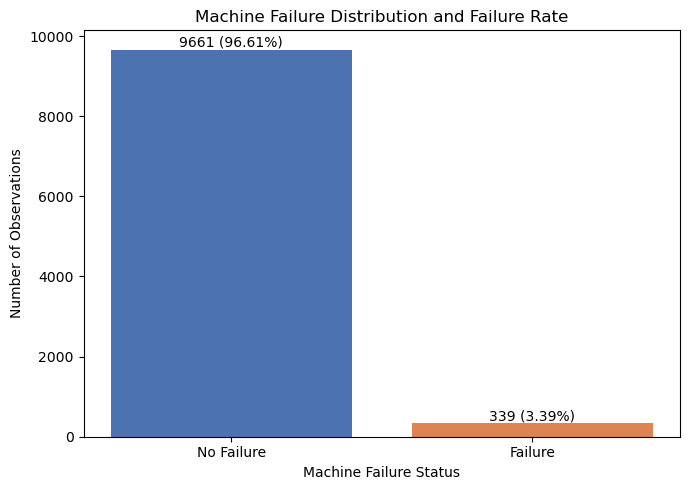

In [5]:
# Count target values and sort them by class label
# This ensures 0 comes before 1 for correct chart ordering
counts = df["Machine failure"].value_counts().sort_index()

# Convert counts to percentages for annotation on the chart
percentages = counts / counts.sum() * 100

# Define custom colors for better visual distinction
# Blue represents no failure, orange represents failure
colors = ["#4C72B0", "#DD8452"]  # blue = no failure, orange = failure

# Create the figure with a defined size
plt.figure(figsize=(7, 5))

# Create the bar chart for machine failure distribution
bars = plt.bar(
    ["No Failure", "Failure"],
    counts,
    color=colors
)

# Add count and percentage labels above each bar
for bar, count, pct in zip(bars, counts, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,   # x-position at center of the bar
        bar.get_height(),                    # y-position at the top of the bar
        f"{count} ({pct:.2f}%)",             # label text
        ha="center",                         # horizontal alignment
        va="bottom"                          # vertical alignment
    )

# Add chart title and axis labels
plt.title("Machine Failure Distribution and Failure Rate")
plt.xlabel("Machine Failure Status")
plt.ylabel("Number of Observations")

# Adjust layout to avoid overlapping elements
plt.tight_layout()

# Display the chart
plt.show()

## Key Observations
- Machine failure events represent a very small proportion of total observations, confirming a **highly imbalanced dataset**.
- This imbalance reflects real-world industrial environments, where failures are rare but costly.
- As a result, predictive models should prioritize **failure detection capability (recall)** over overall accuracy.
